# Matching

ECON526

Paul Schrimpf (University of British Columbia)

# Introduction

## Setting

- Potential outcomes $(Y(0), Y(1))$
- Treatment $D \in \{0,1\}$
- Observe $Y = Y(D)$
- Covariates $X$
- Assume conditional independence $(Y(0),Y(1)) \perp D | X$
- Assume overlap (positivity): $0 < P(D=1|X) < 1$ almost surely

$$
\def\Er{{\mathrm{E}}}
\def\En{{\mathbb{En}}}
\def\cov{{\mathrm{Cov}}}
\def\var{{\mathrm{Var}}}
\def\R{{\mathbb{R}}}
\newcommand\norm[1]{\left\lVert#1\right\rVert}
\def\rank{{\mathrm{rank}}}
\newcommand{\inpr}{ \overset{p^*_{\scriptscriptstyle n}}{\longrightarrow}}
\def\inprob{{\,{\buildrel p \over \rightarrow}\,}}
\def\indist{\,{\buildrel d \over \rightarrow}\,}
\DeclareMathOperator*{\plim}{plim}
\DeclareMathOperator*{\argmin}{argmin}
$$

## Why not regression?

- Average treatment effect $$
  ATE = \int \Er[Y|D=1,X=x] - \Er[Y|D=0,X=x] dP(x)
  $$
- Regression gives the best linear approximation to $\Er[Y|D,X]$, so why
  not just estimate a linear regression $$
  Y_i = \hat{\alpha} D_i + X_i'\hat{\beta} + \hat{\epsilon}_i
  $$ and then use $\hat{\alpha}$ as an estimate of the ATE?

## Why not regression?

- Partial out (Frisch-Waugh-Lovell theorem) $$
  \begin{align*}
  \hat{\alpha} = & \frac{\frac{1}{n} \sum_{i=1}^n Y_i (D_i - X_i'(X'X)^{-1}X'D)}
    {\frac{1}{n} \sum_{i=1}^n (D_i - X_i'(X'X)^{-1}X'D)^2} \\
    \inprob & \Er\left[Y_i \underbrace{\frac{D_i - X_i'\pi}{\Er[(D_i - X_i'\pi)^2]}}_{\equiv \omega(D_i,X_i)}\right] \\
    = & \Er\left[Y_{0,i} \omega(D_i,X_i)\right] + \Er\left[(Y_{1,i}-Y_{0,i}) \omega(D_i,X_i)D_i\right]
  \end{align*}
  $$ where $\pi = \argmin_{\tilde{\pi}} \Er[(D_i - X_i'\tilde{\pi})^2]$

- Note: $\Er[\omega(D,X)] = 0$, $\Er[D\omega(D,X)] = 1$

- $\omega(D,X)$ is only orthogonal to linear functions of $X$, so
  $\Er[Y_{0,i}\omega(D_i,X_i)] \neq 0$ in general when $\Er[Y(0)|X]$ is
  nonlinear

## Why not regression?

- $\plim \hat{\alpha} = \Er\left[Y_{0,i} \omega(D_i,X_i)\right] + \Er\left[(Y_{1,i}-Y_{0,i}) \omega(D_i,X_i)D_i\right]$

- What can be in the range of
  $\omega(D,X) = \frac{D - X'\pi}{\Er[(D_i - X_i'\pi)^2]}$?

## Why not regression?

In [1]:
import numpy as np
from matplotlib import style
from matplotlib import pyplot as plt
import scipy
style.use("fivethirtyeight")

In [2]:
np.random.seed(1234)

def simulate(n, pi=np.array([0,1])):
    X = np.random.randn(n, len(pi))
    X[:,0] = 1
    P = np.clip(scipy.stats.norm.cdf(X @ pi), 0.05, 0.95)
    D = 1*(np.random.rand(n) < P)
    Ey0x = np.zeros(n)
    Ey1x = np.exp(3*(X[:,1]-2))
    y0 = Ey0x + np.random.randn(n)
    y1 = Ey1x + np.random.randn(n)
    y = D*y1 + (1-D)*y0
    return(X,D,y,y0,y1, Ey0x, Ey1x, P)

X,D,y,y0,y1,Ey0x,Ey1x,P = simulate(4000)

pihat = np.linalg.solve(X.T @ X, X.T @ D)
w = D - X @ pihat
w = w/np.mean(w**2);

## Why not regression?

In [3]:
DX = np.hstack((D.reshape(len(D),1),X))
abhat = np.linalg.solve(DX.T @ DX, DX.T @ y)
ahat = abhat[0]
print(ahat)

-0.11952795827329016

In [4]:
np.mean(y1-y0)

np.float64(0.1172689998868494)

- Weights, $\omega(D,X)$, are not all positive, so the regression
  estimate can be negative even if $\Er[Y(1) | X] - \Er[Y(0)|X]$ is
  positive everywhere

## Why not regression?

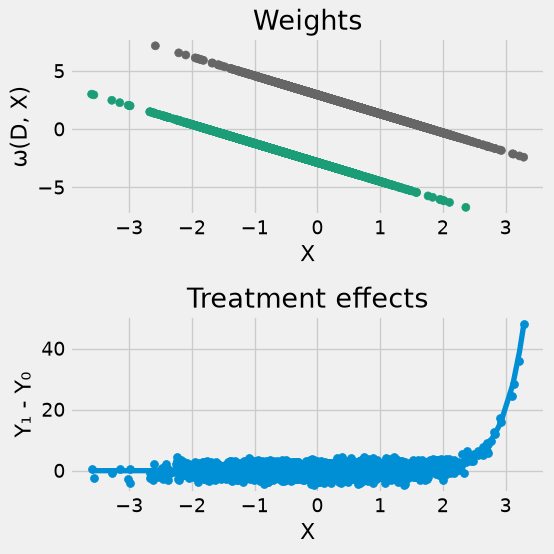

In [5]:
import matplotlib.cm as cm
fig, axes = plt.subplots(2, 1, figsize=(6, 6))

# Create a scatter plot for the first panel (left)
axes[0].scatter(X[:,1], w, c=D, cmap=cm.Dark2)
axes[0].set_xlabel("X")
axes[0].set_ylabel("ω(D, X)")
axes[0].set_title("Weights")

axes[1].scatter(X[:,1], y1-y0, label="TE")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y₁ - Y₀")
axes[1].set_title("Treatment effects")
sort_idx = np.argsort(X[:,1])
axes[1].plot(X[sort_idx,1], Ey1x[sort_idx]-Ey0x[sort_idx], label="E[y1-y0|x]")

# Display the plot
plt.tight_layout()  # Ensure proper layout spacing
plt.show()

# Matching

## Matching

- If not regression, then what? $$
  ATE = \int \Er[Y|D=1,X=x] - \Er[Y|D=0,X=x] dP(x)
  $$

## Plug-in estimator

- Plug-in estimator: $$
  \widehat{ATE} = \frac{1}{n} \sum_{i=1}^n \left(\hat{E}[Y|D=1,X=X_i] - \hat{E}[Y|D=0,X=X_i] \right)
  $$ where $\hat{E}[Y|D,X]$ is some flexible estimator for $\Er[Y|D,X]$
  - if $X$ is discrete, $\hat{E}$ can be conditional averages or
    equivalently, “saturated” regression
  - if $X$ is continuous, $\hat{E}$ can be some nonparametric regression
    estimator
  - Original approaches to this problem used nearest neighbor matching
    to estimate $\hat{E}[Y|D,X]$
- Downside:
  - Difficult statistical properties — choice of tuning parameters,
    strong assumptions needed, failure of the bootstrap for nearest
    neighbors Abadie and Imbens (2008)

## Propensity Score

- Let $p(X) = P(D=1|X)$
- Note: $$
  \begin{align*}
  \Er[Y|X,D=1] - \Er[Y|X,D=0] = & E\left[\frac{Y D}{p(X)}|X \right] - E\left[\frac{Y(1-D)}{1-p(X)}|X \right] \\
  = & E\left[ Y \frac{D - p(X)}{p(X)(1-p(X))} | X \right]
  \end{align*}
  $$

## Propensity Score

- so $$
  ATE = \Er\left[ \frac{Y D}{p(X)} -  \frac{Y(1-D)}{1-p(X)}\right] = \Er\left[ Y \frac{D - p(X)}{p(X)(1-p(X))} \right]
  $$

## Inverse propensity weighting

- Estimator $$
  \widehat{ATE}^{IPW} = \frac{1}{n} \sum_{i=1}^n \frac{Y_iD_i}{\hat{p}(X_i)} - \frac{Y_i(1-D_i)}{1-\hat{p}(X_i)}
  $$ where $\hat{p}(X)$ is some flexible estimator for $P(D=1|X)$

- Downside:

  - Difficult statistical properties — choice of tuning parameters,
    strong assumptions needed

## Doubly Robust Estimator

- Combines plug-in and IPW estimators
- Estimator $$
  \begin{align*}
  \widehat{ATE}^{DR} = & \frac{1}{n} \sum_{i=1}^n \hat{E}[Y|D=1,X=X_i] - \hat{E}[Y|D=0,X=X_i] + \\
  & + \frac{1}{n} \sum_{i=1}^n  \frac{D_i(Y_i - \hat{E}[Y|D=1,X=X_i])}{\hat{p}(X_i)} - \\
  & - \frac{(1-D_i)(Y_i - \hat{E}[Y|D=0,X=X_i])} {1-\hat{p}(X_i)}
  \end{align*}
  $$

## Doubly Robust Estimator

- Doubly robust in that:
  - Consistent as long as either $\hat{p}(X) \inprob p(X)$ or
    $\hat{E}[Y|D,X] \inprob \Er[Y|D,X]$
  - Insensitive to small changes in $\hat{p}(X)$ or $\hat{E}[Y|D,X]$
- Allows nicer statistical properties
  - Weaker assumptions needed
  - Uses **cross-fitting** (sample splitting) so overfitting in
    $\hat{p}(X)$ or $\hat{E}[Y|D,X]$ does not bias the ATE
  - Asymptotic distribution is the same as if $p(X)$ and $\Er[Y|D,X]$
    were known

## Software

- Advice: use the doubly robust estimator with nonparametric estimates
  for $\hat{E}[Y|D,X]$ and $\hat{p}(X)$
- Recommended package:
  - [doubleml](https://docs.doubleml.org/stable/guide/models.html#interactive-regression-models-irm)

## Example: simulation

- Infeasible estimator: average of $Y(1) - Y(0)$

In [6]:
se = np.sqrt(np.var(y1-y0)/len(y1))
ate = np.mean(y1-y0)
print(f"Infeasible estimator with potential outcomes observed = {ate:.2} with 95% CI = [{ate-1.96*se:.2},{ate+1.96*se:.2}]\n")

Infeasible estimator with potential outcomes observed = 0.12 with 95% CI = [0.058,0.18]


## Example: choosing flexible estimators

In [7]:
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.linear_model import LassoCV, LogisticRegressionCV, ElasticNetCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.kernel_approximation import RBFSampler
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

gamma = 0.5
nc = 100
models = [
    Pipeline([('rbf',RBFSampler(gamma=gamma, random_state=1, n_components=nc)),
              ('lasso',LassoCV(max_iter=10_000, tol=1e-2, n_jobs=-1, selection='random',
                               alphas=10**np.linspace(-3,3,20)))]),
    Pipeline([('poly',PolynomialFeatures(degree=10)),
              ('scale', StandardScaler()),
              ('lasso',LassoCV(max_iter=10_000, n_jobs=-1, selection='random', tol=1e-2,
                               alphas=10**np.linspace(-3,3,20)))]),
    GradientBoostingRegressor(learning_rate=0.1, criterion="squared_error")]

for m in models :
    print(m)
    print(f"cross val R-squared {cross_val_score(m, X, y, cv=5).mean():.4} \n\n")

Pipeline(steps=[('rbf', RBFSampler(gamma=0.5, random_state=1)),
                ('lasso',
                 LassoCV(alphas=array([1.00000000e-03, 2.06913808e-03, 4.28133240e-03, 8.85866790e-03,
       1.83298071e-02, 3.79269019e-02, 7.84759970e-02, 1.62377674e-01,
       3.35981829e-01, 6.95192796e-01, 1.43844989e+00, 2.97635144e+00,
       6.15848211e+00, 1.27427499e+01, 2.63665090e+01, 5.45559478e+01,
       1.12883789e+02, 2.33572147e+02, 4.83293024e+02, 1.00000000e+03]),
                         max_iter=10000, n_jobs=-1, selection='random',
                         tol=0.01))])
cross val R-squared 0.4365 


Pipeline(steps=[('poly', PolynomialFeatures(degree=10)),
                ('scale', StandardScaler()),
                ('lasso',
                 LassoCV(alphas=array([1.00000000e-03, 2.06913808e-03, 4.28133240e-03, 8.85866790e-03,
       1.83298071e-02, 3.79269019e-02, 7.84759970e-02, 1.62377674e-01,
       3.35981829e-01, 6.95192796e-01, 1.43844989e+00, 2.97635144e+00,
       6

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/ensemble/_gb.py:666: FutureWarning: The parameter `criterion` is deprecated and will be removed in 1.11. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/ensemble/_gb.py:666: FutureWarning: The parameter `criterion` is deprecated and will be removed in 1.11. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/ensemble/_gb.py:666: FutureWarning: The parameter `criterion` is deprecated and will be removed in 1.11. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/ensemble/_gb.py:666: FutureWarning: The parameter `criterion` is deprecated and will be removed in 1.11. It has no effect. Leave it to its default value to avoid this wa

cross val R-squared 0.5006 



/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/ensemble/_gb.py:666: FutureWarning: The parameter `criterion` is deprecated and will be removed in 1.11. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(

## Visualizing Fit

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/ensemble/_gb.py:666: FutureWarning: The parameter `criterion` is deprecated and will be removed in 1.11. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(

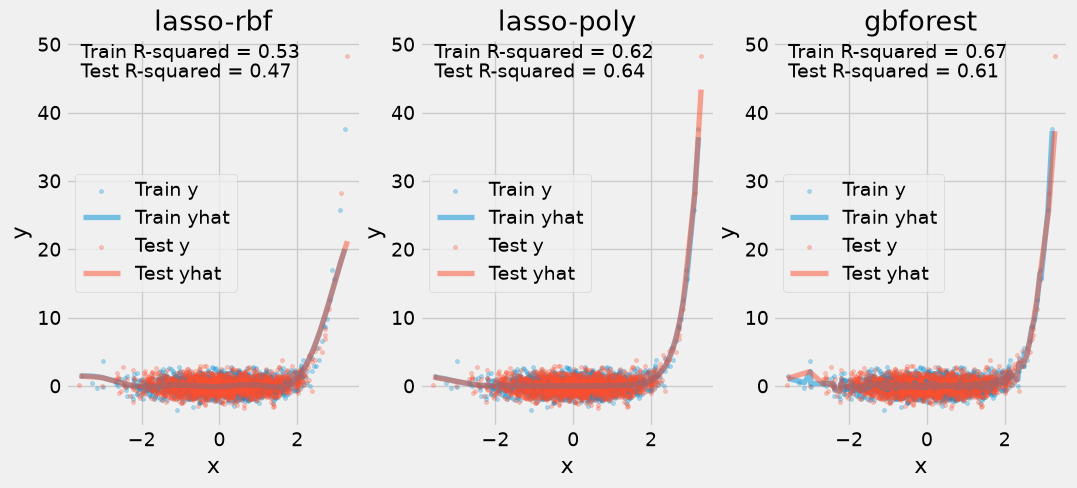

In [8]:
from sklearn.model_selection import train_test_split
names = ["lasso-rbf", "lasso-poly", "gbforest"]
X_train,  X_test,y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=5498)
fig, ax = plt.subplots(1,3, figsize=(12,5))
ax = ax.flatten()
def r2(y,yhat) :
    return(1 - np.mean((y-yhat)**2)/np.var(y))
otr = np.argsort(X_train[:,1])
ote = np.argsort(X_test[:,1])

for i, m in enumerate(models):
    m.fit(X_train,y=y_train)
    yhat = m.predict(X_train)
    yhat_test = m.predict(X_test)
    ax[i].scatter(X_train[:,1], y_train, alpha=0.3, label="Train y", color="C0", marker=".")
    ax[i].plot(X_train[otr,1], yhat[otr], alpha=0.5, label="Train yhat", color="C0")
    ax[i].scatter(X_test[:,1], y_test, alpha=0.3, label="Test y", color="C1", marker=".")
    ax[i].plot(X_test[ote,1], yhat_test[ote], alpha=0.5, label="Test yhat", color="C1")
    ax[i].set_xlabel("x")
    ax[i].set_ylabel("y")
    ax[i].set_title(names[i])
    ax[i].annotate(f"Train R-squared = {r2(y_train, yhat):.2}", (0.05, 0.95), xycoords='axes fraction')
    ax[i].annotate(f"Test R-squared = {r2(y_test, yhat_test):.2}", (0.05, 0.90), xycoords='axes fraction')
    ax[i].legend()

plt.show()

## Example: choosing flexible estimators

In [9]:
gamma = 0.5
nc = 100
models = [
    Pipeline([('rbf',RBFSampler(gamma=gamma, random_state=1, n_components=nc)),
              ('logistic',LogisticRegressionCV(n_jobs=-1, scoring='neg_log_loss'))]),
    Pipeline([('poly',PolynomialFeatures(degree=10)),
              ('scale', StandardScaler()),
              ('logistic',LogisticRegressionCV(n_jobs=-1, scoring='neg_log_loss'))]),
    GradientBoostingClassifier(learning_rate=0.1)]
for m in models :
    print(m)
    print(f"cross val log likelihood {cross_val_score(m, X, D, scoring='neg_log_loss', cv=5).mean():.4} \n\n")

Pipeline(steps=[('rbf', RBFSampler(gamma=0.5, random_state=1)),
                ('logistic',
                 LogisticRegressionCV(n_jobs=-1, scoring='neg_log_loss'))])

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
/home/paul/526/site/.venv/lib/p

cross val log likelihood -0.5077 


Pipeline(steps=[('poly', PolynomialFeatures(degree=10)),
                ('scale', StandardScaler()),
                ('logistic',
                 LogisticRegressionCV(n_jobs=-1, scoring='neg_log_loss'))])

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
/home/paul/526/site/.venv/lib/p

cross val log likelihood -0.5098 


GradientBoostingClassifier()
cross val log likelihood -0.5184 



## Example: Checking Overlap

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(

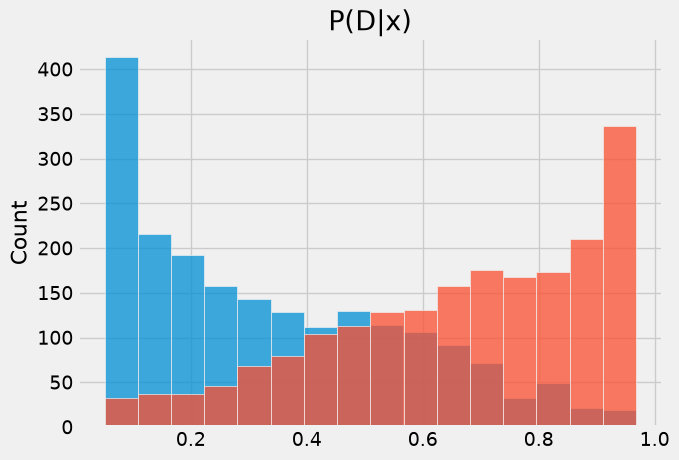

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
import doubleml as dml
g = Pipeline([('poly',PolynomialFeatures(degree=10)),
              ('scale', StandardScaler()),
              ('lasso',LassoCV(max_iter=10_000, n_jobs=-1, selection='random', tol=1e-2,
                               alphas=10**np.linspace(-3,3,20)))])
m = Pipeline([('rbf',RBFSampler(gamma=gamma, random_state=1, n_components=nc)),
              ('logistic',LogisticRegressionCV(n_jobs=-1, scoring='neg_log_loss'))])

m.fit(X,D)

def plotp(model,X,d):
    fig,ax=plt.subplots()
    p = model.predict_proba(X)
    sns.histplot(p[d==0,1], kde = False,
                 label = "Untreated", ax=ax)
    sns.histplot(p[d==1,1], kde = False,
                 label = "Treated", ax=ax)
    ax.set_title('P(D|x)')
    return(fig)

fig=plotp(m, X, D)

- We want the treated and untreated propensity score distributions to
  overlap and stay away from $0$ and $1$; values near $0$ or $1$ produce
  extreme IPW weights.

## Example: Results

In [11]:
dmldata = dml.DoubleMLData.from_arrays(X, y, D)
dmlATE = dml.DoubleMLAPOS(dmldata, g, m, treatment_levels=[0, 1])
dmlATE.fit()
dmlATE.summary

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
/home/paul/526/site/.venv/lib/p

In [12]:
dmlATE.causal_contrast(0).summary

In [13]:
aipw = Ey1x - Ey0x + D*(y - Ey1x)/P - (1-D)*(y - Ey0x)/(1-P)
se = np.sqrt(np.var(aipw)/len(aipw))
print(f"Infeasible estimator with true E[y1-y0|x] and p(x) = {np.mean(aipw):.2} with 95% CI = [{np.mean(aipw)-1.96*se:.2},{np.mean(aipw)+1.96*se:.2}]\n")

Infeasible estimator with true E[y1-y0|x] and p(x) = 0.15 with 95% CI = [0.057,0.24]


# Growth Mindset

## National Study of Learning Mindsets

- Original study by Yeager et al. (2019)
- Synthetic data created by Athey and Wager (2019), downloaded from
  Facure (2022)

## Data

In [14]:
import pandas as pd
import numpy as np
from matplotlib import style
from matplotlib import pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
style.use("fivethirtyeight")
pd.set_option("display.max_columns", 20)
datadir="./data"

In [15]:
data = pd.read_csv(datadir+"/learning_mindset.csv")
data.sample(5, random_state=431)

## Evidence of Confounding

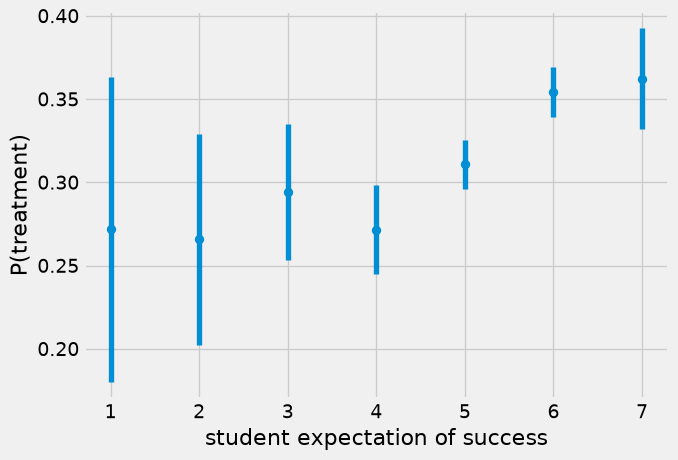

In [16]:
def std_error(x):
    return np.std(x, ddof=1) / np.sqrt(len(x))

grouped = data.groupby('success_expect')['intervention'].agg(['mean', std_error])
grouped = grouped.reset_index()

fig, ax = plt.subplots()
plt.errorbar(grouped['success_expect'],grouped['mean'],yerr=1.96*grouped['std_error'],fmt="o")
ax.set_xlabel('student expectation of success')
ax.set_ylabel('P(treatment)')
plt.show()

## Unadjusted estimate of ATE

In [17]:
print(smf.ols("achievement_score ~ intervention", data=data).fit(cov_type="HC3").summary().tables[1])

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -0.1538      0.012    -13.289      0.000      -0.176      -0.131
intervention     0.4723      0.021     22.968      0.000       0.432       0.513

In [18]:
print(smf.ols("achievement_score ~ intervention", data=data).fit(
    cov_type="cluster", cov_kwds={'groups': data['schoolid']}).summary().tables[1])

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -0.1538      0.036     -4.275      0.000      -0.224      -0.083
intervention     0.4723      0.025     19.184      0.000       0.424       0.521

## Unadjusted estimate of ATE

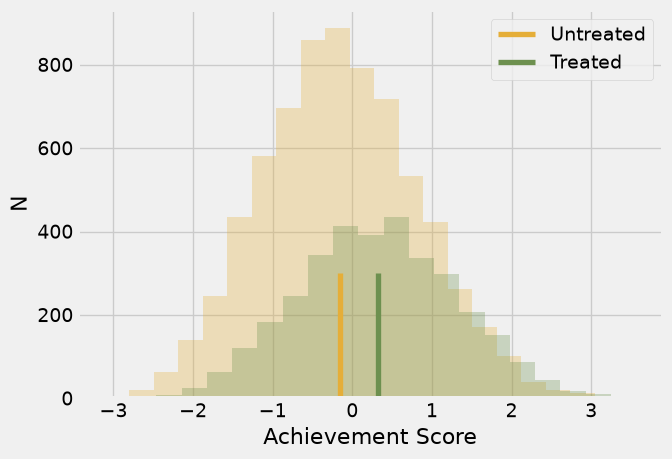

In [19]:
fig,ax=plt.subplots()
plt.hist(data.query("intervention==0")["achievement_score"], bins=20, alpha=0.3, color="C2")
plt.hist(data.query("intervention==1")["achievement_score"], bins=20, alpha=0.3, color="C3")
plt.vlines(-0.1538, 0, 300, label="Untreated", color="C2")
plt.vlines(-0.1538+0.4723, 0, 300, label="Treated", color="C3")
ax.set_xlabel("Achievement Score")
ax.set_ylabel("N")
plt.legend()
plt.show();

## Regression estimate of ATE

In [20]:
ols = smf.ols("achievement_score ~ intervention + success_expect + ethnicity + gender + frst_in_family + school_urbanicity + school_mindset + school_achievement + school_ethnic_minority + school_poverty + school_size",data=data).fit(cov_type="cluster", cov_kwds={'groups': data['schoolid']})
print(ols.summary().tables[1])

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -1.7786      0.110    -16.214      0.000      -1.994      -1.564
intervention               0.3964      0.025     15.558      0.000       0.346       0.446
success_expect             0.3746      0.009     41.120      0.000       0.357       0.392
ethnicity                  0.0043      0.003      1.639      0.101      -0.001       0.009
gender                    -0.2684      0.016    -16.299      0.000      -0.301      -0.236
frst_in_family            -0.1310      0.019     -6.770      0.000      -0.169      -0.093
school_urbanicity          0.0573      0.036      1.613      0.107      -0.012       0.127
school_mindset            -0.1484      0.044     -3.341      0.001      -0.235      -0.061
school_achievement        -0.0253      0.055     -0.457      0.647      -0.134       0.083

## Regression estimate of ATE: weights

In [21]:
lpm = smf.ols("intervention ~ success_expect + ethnicity + gender + frst_in_family + school_urbanicity + school_mindset + school_achievement + school_ethnic_minority + school_poverty + school_size",data=data).fit(cov_type="cluster", cov_kwds={'groups': data['schoolid']})
w = lpm.resid / np.var(lpm.resid)
print(np.mean(data.achievement_score*w))

0.3964023603338951

## Regression estimate of ATE: weights

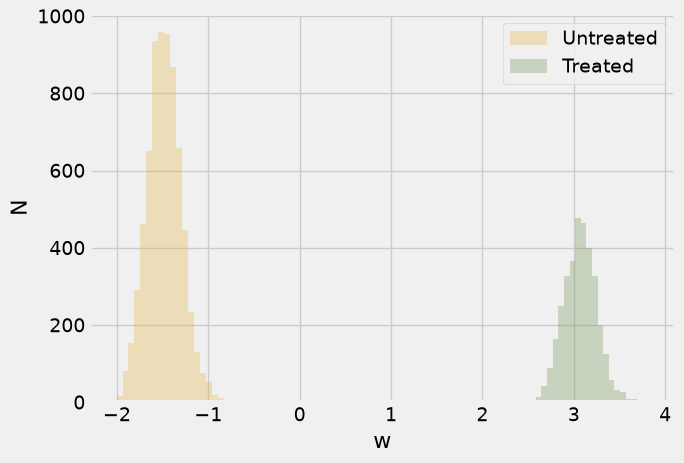

In [22]:
fig,ax=plt.subplots()
plt.hist(w[data.intervention==0], bins=20, alpha=0.3, color="C2", label="Untreated")
plt.hist(w[data.intervention==1], bins=20, alpha=0.3, color="C3", label="Treated")
ax.set_xlabel("w")
ax.set_ylabel("N")
plt.legend()
plt.show();

## Propensity Score Matching

In [23]:
categ = ["ethnicity", "gender", "school_urbanicity","success_expect"]
cont = ["school_mindset", "school_achievement", "school_ethnic_minority", "school_poverty", "school_size"]

data_with_categ = pd.concat([
    data.drop(columns=categ), # dataset without the categorical features
    pd.get_dummies(data[categ], columns=categ, drop_first=False)# categorical features converted to dummies
], axis=1)

print(data_with_categ.shape)
D = 'intervention'
Y = 'achievement_score'
X = data_with_categ.columns.drop(['schoolid', D, Y])

(10391, 38)

## Propensity Score Matching

In [24]:
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.neighbors import KNeighborsRegressor
import sklearn

def propensitymatching(D,Y,X,psmodel=LogisticRegressionCV(scoring='neg_log_loss'),neighbormodel=KNeighborsRegressor(n_neighbors=1,algorithm='auto',weights='uniform')):
    pfit = psmodel.fit(X,D)
    ps = pfit.predict_proba(X)[:,1]
    ey1 = neighbormodel.fit(ps[D==1].reshape(-1,1),Y[D==1])
    ey0 = sklearn.base.clone(neighbormodel).fit(ps[D==0].reshape(-1,1),Y[D==0])
    tex = ey1.predict(ps.reshape(-1,1)) - ey0.predict(ps.reshape(-1,1))
    ate = np.mean(tex)
    return(ate, tex,ps)

ate,tex,ps=propensitymatching(data_with_categ[D],data_with_categ[Y],data_with_categ[X])
print(ate)

0.4159743197051149

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(

## Propensity Score Matching

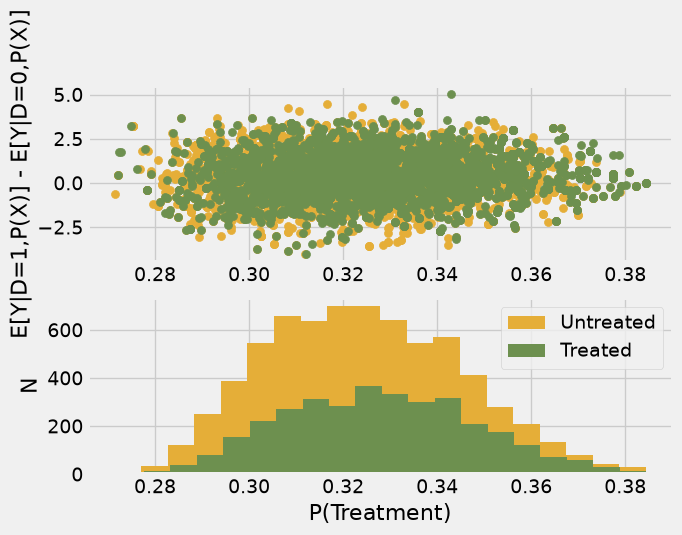

In [25]:
fig, ax = plt.subplots(2,1)
treat = data.intervention
ax[0].scatter(ps[treat==0],tex[treat==0],color="C2")
ax[0].scatter(ps[treat==1],tex[treat==1],color="C3")
ax[1].hist(ps[treat==0],bins=20,color="C2",label="Untreated")
ax[1].hist(ps[treat==1],bins=20,color="C3",label="Treated")
ax[1].set_xlabel("P(Treatment)")
ax[1].set_ylabel("N")
ax[0].set_ylabel("E[Y|D=1,P(X)] - E[Y|D=0,P(X)]")
plt.legend()
plt.show()

## Inverse Propensity Weighting

In [26]:
def ipw(D,Y,X,psmodel=LogisticRegressionCV(scoring='neg_log_loss')):
    pfit = psmodel.fit(X,D)
    ps = pfit.predict_proba(X)[:,1]
    ate=np.mean(Y*(D - ps)/(ps*(1-ps)))
    return(ate,ps)

ate,ps = ipw(data_with_categ[D],data_with_categ[Y],data_with_categ[X])
print(ate)

0.44256557543538383

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(

## Doubly Robust

In [27]:
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.linear_model import LassoCV, LogisticRegressionCV, ElasticNetCV
from sklearn.preprocessing import PolynomialFeatures

def robustate(D,Y,X,psmodel=LogisticRegressionCV(scoring='neg_log_loss'),ymodel=LassoCV(), cluster=None):
    pfit = psmodel.fit(X,D)
    ps = pfit.predict_proba(X)[:,1]
    ey1fit = ymodel.fit(X[D==1],Y[D==1])
    ey0fit = sklearn.base.clone(ymodel).fit(X[D==0],Y[D==0])
    ey1 = ey1fit.predict(X)
    ey0 = ey0fit.predict(X)
    ate_terms = ey1 - ey0 + D*(Y- ey1)/ps - (1-D)*(Y-ey0)/(1-ps)
    ate = np.mean(ate_terms)
    # check if cluster is None
    if cluster is None :
        ate_se = np.sqrt(np.var(ate_terms)/len(ate_terms))
    else :
        creg=smf.ols("y ~ 1", pd.DataFrame({"y" : ate_terms})).fit(cov_type="cluster", cov_kwds={'groups': cluster})
        ate_se = np.sqrt(creg.cov_params().iloc[0,0])

    return(ate, ate_se, ps, ey1,ey0)

ate,se,ps,ey1,ey0 = robustate(data_with_categ[D],data_with_categ[Y],data_with_categ[X],cluster=data_with_categ['schoolid'])
print(ate-1.96*se, ate, ate+1.96*se)

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(

0.3317146398974233 0.3832790165781085 0.4348433932587937

[1]

## Doubly Robust

- Better to use the `doubleml` package

[1] We have glossed over **cross-fitting** (sample splitting), which is
needed for doubly robust estimation with flexible/ML nuisance estimators
to have nice statistical properties. It is not implemented above; it is
better to use `doubleml` instead.

In [28]:
import doubleml as dml

g = LassoCV()
m = LogisticRegressionCV(scoring='neg_log_loss')
dmldata = dml.DoubleMLClusterData(
    data_with_categ, y_col=Y, d_cols=D, x_cols=X.to_list(), cluster_cols='schoolid'
)
dmlATE = dml.DoubleMLIRM(dmldata, g, m)
dmlATE.fit()
dmlATE.summary

/tmp/ipykernel_4092438/4243603964.py:5: FutureWarning: DoubleMLClusterData is deprecated and will be removed with version 0.12.0. Use DoubleMLData with cluster_cols instead.
  dmldata = dml.DoubleMLClusterData(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time 

## Summary of Growth Mindset Results

- Unadjusted difference in means ($\approx 0.47$) overstates the effect
  due to positive selection into treatment (e.g., students with higher
  success expectations are more likely to be treated).
- Adjusting for covariates via multivariate OLS ($\approx 0.40$),
  propensity score matching, IPW, and doubly robust / `doubleml`
  ($\approx 0.38$) yields slightly smaller, consistent estimates.
- Clustering standard errors by `schoolid` accounts for within-school
  correlation in both OLS and `doubleml`.

## Do Growth Mindset Interventions Work?

- **No broad consensus**, though both sides agree the **average effect
  across all students is very small** ($d \approx 0.04\text{--}0.05$).
- **Skeptical view:** Meta-analyses by Sisk et al. (2018) and Macnamara
  and Burgoyne (2023) find weak overall effects that become
  statistically indistinguishable from zero after adjusting for
  publication bias, study quality, and researcher incentives.
- **Heterogeneity / targeted view:** Yeager et al. (2019) find modest
  gains among lower-achieving students ($d \approx 0.11$), and Burnette
  et al. (2023) report positive effects for targeted/at-risk groups with
  high-fidelity implementation ($d \approx 0.14$ for achievement;
  $d \approx 0.32$ for mental health).
- **Methodological debate:** Tipton et al. (2023) argue that pooling
  heterogeneous studies into a single grand mean obscures real subgroup
  effects, whereas critics argue those subgroup effects do not survive
  strict bias adjustments.

## Sources and Further Reading

- Useful additional reading is [chapters
  10-12](https://matheusfacure.github.io/python-causality-handbook/10-Matching.html)
  of Facure (2022) and [chapter
  14](https://theeffectbook.net/ch-Matching.html) of Huntington-Klein
  (2021).[1]

- Chapters 5 and 10 of Chernozhukov et al. (2024)

- The representation of the estimate from a linear model as a weighted
  average is based on Borusyak and Jaravel (2018)

- The growth mindset example is taken from Facure (2022)

## References

Abadie, Alberto, and Guido W. Imbens. 2008. “On the Failure of the
Bootstrap for Matching Estimators.” *Econometrica* 76 (6): 1537–57.
https://doi.org/<https://doi.org/10.3982/ECTA6474>.

Athey, Susan, and Stefan Wager. 2019. *Estimating Treatment Effects with
Causal Forests: An Application*.

Borusyak, Kirill, and Xavier Jaravel. 2018. *Revisiting Event Study
Designs*.
<https://scholar.harvard.edu/files/borusyak/files/borusyak_jaravel_event_studies.pdf>.

Burnette, Jeni L., Joseph Billingsley, George C. Banks, et al. 2023. “A
Systematic Review and Meta-Analysis of Growth Mindset Interventions: For
Whom, How, and Why Might Such Interventions Work?” *Psychological
Bulletin* 149 (3-4): 174–205. <https://doi.org/10.1037/bul0000368>.

Chernozhukov, V., C. Hansen, N. Kallus, M. Spindler, and V. Syrgkanis.
2024. *Applied Causal Inference Powered by ML and AI*.
<https://causalml-book.org/>.

Facure, Matheus. 2022. *Causal Inference for the Brave and True*.
<https://matheusfacure.github.io/python-causality-handbook/landing-page.html>.

Huntington-Klein, Nick. 2021. *The Effect: An Introduction to Research
Design and Causality*. CRC Press. <https://theeffectbook.net/>.

Macnamara, Brooke N., and Alexander P. Burgoyne. 2023. “Do Growth
Mindset Interventions Impact Students’ Academic Achievement? A
Systematic Review and Meta-Analysis with Recommendations for Best
Practices.” *Psychological Bulletin* 149 (3-4): 133–73.
<https://doi.org/10.1037/bul0000352>.

Sisk, Victoria F., Alexander P. Burgoyne, Jingze Sun, Jennifer L.
Butler, and Brooke N. Macnamara. 2018. “To What Extent and Under Which
Circumstances Are Growth Mind-Sets Important to Academic Achievement?
Two Meta-Analyses.” *Psychological Science* 29 (4): 549–71.
<https://doi.org/10.1177/0956797617739704>.

Tipton, Elizabeth, Christopher J. Bryan, Jared Murray, Michael McDaniel,
Barbara Schneider, and David S. Yeager. 2023. “Why Meta-Analyses of
Growth Mindset and Other Interventions Should Follow Best Practices for
Examining Heterogeneity: Commentary on Macnamara and Burgoyne (2023) and
Burnette Et Al. (2023).” *Psychological Bulletin* 149 (3-4): 229–41.
<https://doi.org/10.1037/bul0000384>.

Yeager, David S., Paul Hanselman, Gregory M. Walton, et al. 2019. “A
National Experiment Reveals Where a Growth Mindset Improves
Achievement.” *Nature* 573 (7774): 364–69.
<https://doi.org/10.1038/s41586-019-1466-y>.

[1] Overlap and covariate balance are very important in practice. The
readings, especially Huntington-Klein (2021), cover them pretty well.